In [ ]:
from c3po.tables.dev_tables import C3POStorage
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
latent_period = 3.0

# t = np.arange(0, t_max, 0.001)
# theta = np.mod(t, latent_period) / latent_period * 2 * np.pi

#
from c3po.analysis.analysis import figure_directory
from pathlib import Path
import os
figure_directory = Path(figure_directory)
figure_folder = figure_directory / "Fig_1"
os.makedirs(figure_folder, exist_ok=True)

C3POStorage() & "model_name LIKE '%dim_sweep%'"

/home/sambray/.local/lib/python3.10/site-packages/datajoint/plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # requires setuptools<82
[2026-10-20 06:51:13,522][INFO]: DataJoint 0.14.9 connected to sambray@lmf-db.cin.ucsf.edu:3306


model_name,encoder_args,context_args,rate_args,latent_dim,context_dim,input_shape,learned_params
periodic_toy_model_non_coding_units_v2_dim_sweep_12d,=BLOB=,=BLOB=,=BLOB=,12,12,=BLOB=,=BLOB=
periodic_toy_model_non_coding_units_v2_dim_sweep_16d,=BLOB=,=BLOB=,=BLOB=,16,16,=BLOB=,=BLOB=
periodic_toy_model_non_coding_units_v2_dim_sweep_20d,=BLOB=,=BLOB=,=BLOB=,20,20,=BLOB=,=BLOB=
periodic_toy_model_non_coding_units_v2_dim_sweep_24d,=BLOB=,=BLOB=,=BLOB=,24,24,=BLOB=,=BLOB=
periodic_toy_model_non_coding_units_v2_dim_sweep_2d,=BLOB=,=BLOB=,=BLOB=,2,2,=BLOB=,=BLOB=
periodic_toy_model_non_coding_units_v2_dim_sweep_32d,=BLOB=,=BLOB=,=BLOB=,32,32,=BLOB=,=BLOB=
periodic_toy_model_non_coding_units_v2_dim_sweep_4d,=BLOB=,=BLOB=,=BLOB=,4,4,=BLOB=,=BLOB=
periodic_toy_model_non_coding_units_v2_dim_sweep_8d,=BLOB=,=BLOB=,=BLOB=,8,8,=BLOB=,=BLOB=


In [3]:
query = C3POStorage() & "model_name LIKE '%dim_sweep%'"
all_model = {}
for key in tqdm(query.fetch("KEY")):
    dim = (query & key).fetch1("latent_dim")
    if dim in all_model:
        continue
    analysis = (C3POStorage & key).fetch_analysis_object()
    analysis.load_embedding(f"/stelmo/sam/c3po_results/{key['model_name']}_embedding.npz")
    context_dim = analysis.context_dim
    latent_dim = analysis.latent_dim

    t_interp = np.arange(analysis.t[0], analysis.t[-1], 0.001)
    analysis.interpolate_context(t_interp)
    analysis.fit_context_pca(interpolated=True)

    all_model[dim] = analysis


  0%|          | 0/8 [00:00<?, ?it/s]2026-10-20 06:51:28.617066: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-20 06:51:30.031612: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-20 06:51:31.135396: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-20 06:51:32.5554

In [ ]:
to_plot = [2,4,8,12,16,20,24,32]
max_dims = 64

theta_bins = np.linspace(0, 2*np.pi, 100)
nrows = min(max_dims, max(to_plot))
ncols = len(to_plot)

all_results = {}
for i, dim in tqdm(enumerate(to_plot)):
    analysis = all_model[dim]
    # break

    t_max = analysis.t[-1]
    t = np.arange(0, t_max, 0.001)
    theta = np.mod(t, latent_period) / latent_period * 2 * np.pi
    results, _ =analysis.bin_context_by_feature(
        feature = theta,
        feature_times = t_interp,
        bins = theta_bins,
        pca=True,
    )
    # mid = np.array([np.nanmean(xx, axis=0) for xx in results])
    r = np.array([np.nanpercentile(xx, [25, 50, 75], axis=0) for xx in results])
    all_results[dim] = r


8it [00:09,  1.15s/it]


In [9]:
mid.shape

(99, 2)

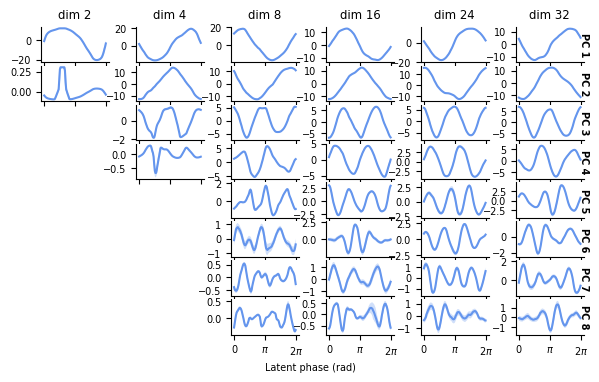

In [33]:
to_plot = [2,4,8,12,16,20,24,32]
to_plot = [2,4,8,16,24,32]
max_dims = 8
nrows = min(max_dims, max(to_plot))
ncols = len(to_plot)
plt.rcParams['font.size']=7
plt.rcParams['svg.fonttype'] = 'none'

fig, ax = plt.subplots(nrows =nrows, ncols=ncols,
                    #    figsize = (ncols*1, nrows*.5),
                    figsize = (7, nrows*.5),
                       sharex=True,
                    #    sharey='row',
                    gridspec_kw = {'hspace': 0.1, 'wspace': 0.4}
                       )

for i, (dim) in enumerate(to_plot):
    r = all_results[dim]
    mid = r[:,1,:]
    low = r[:,0,:]
    high = r[:,2,:]
    for j, ax_ in enumerate(ax[:,i]):
        if j >= dim:
            ax_.axis('off')
            continue
        color = 'cornflowerblue'
        ax_.plot(theta_bins[:-1], mid[:,j], color=color)
        ax_.fill_between(theta_bins[:-1], low[:,j], high[:,j], alpha=0.3, facecolor=color)
        ax_.spines[['top', 'right']].set_visible(False)
        ax_.set_xticks([0, np.pi, 2*np.pi], labels=['0', r'$\pi$', r'$2\pi$'])
    # ax_.set_title(f"dim {dim}, PC {j+1}")
for i, ax_ in enumerate(ax[:,-1]):
    ax_.set_ylabel(f"PC {i+1}", rotation=-90, ha='center', va='bottom', fontweight='bold')
    ax_.yaxis.set_label_position("right")

for i, ax_ in enumerate(ax[0,:]):
    ax_.set_title(f"dim {to_plot[i]}")

ax[-1,2].set_xlabel("Latent phase (rad)",ha='left')

fig.savefig(figure_folder / "dimensionality_analysis.svg", dpi=300, bbox_inches='tight')

In [30]:
fig_dir

NameError: name 'fig_dir' is not defined